<a href="https://colab.research.google.com/github/amiiiiiitz/problem-solving/blob/main/AI-ML/ML3_PP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Problem 1: Data Leakage Identification & Correction**

**Scenario:**
An analyst wrote the following code to impute missing values:
```python
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')
imputer = SimpleImputer(strategy='median')
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
```

**Task:**
1. Identify the data leakage issue in this code.
2. Explain why it causes problems for validation.
3. Write the corrected, leak-free code.

In [3]:
### Problem 1: Data Leakage Issue

# 1. Identification of the data leakage issue:
# The issue is that SimpleImputer is fitted on the entire dataset (df[['Age', 'Salary']]) *before* splitting
# the data into training and test sets. This leads to "information leakage" because the median values used
# to impute the training data and the test data are computed using both training and testing samples.
# During evaluation, the model's test performance will be overly optimistic, and it may fail in production.

# 2. Corrected code:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Load data
df = pd.read_csv('data.csv')

# Split features and target first
X = df.drop('Target', axis=1)
y = df['Target']

# Split into train and test sets first to avoid leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the imputer ONLY on training data, and transform both train and test sets
imputer = SimpleImputer(strategy='median')

# Fit and transform training set
X_train[['Age', 'Salary']] = imputer.fit_transform(X_train[['Age', 'Salary']])

# Transform test set using the learned training medians
X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])


### **Problem 2: Missing Value Analysis**

**Task:**
Using the dataset `data.csv`, write python code to identify and present:
1. The total count of missing values in each column.
2. The percentage of missing values per column.
3. A list of columns that have more than 50% missing values.

In [4]:
### Problem 2: Missing Value Analysis
import pandas as pd

# Read data
df = pd.read_csv('data.csv')

# 1. Total missing values in each column
total_missing = df.isnull().sum()

# 2. Percentage of missing values per column
pct_missing = (df.isnull().sum() / len(df)) * 100

# Combine results into a summary DataFrame
missing_summary = pd.DataFrame({
    'Total Missing': total_missing,
    'Percentage Missing (%)': pct_missing
})

print("--- Missing Values Summary ---")
display(missing_summary)

# 3. Which columns have more than 50% missing values?
cols_over_50 = pct_missing[pct_missing > 50].index.tolist()
print(f"\nColumns with more than 50% missing values: {cols_over_50}")


--- Missing Values Summary ---


,Total Missing,Percentage Missing (%)
Age,180,18.0
Income,150,15.0
Salary,0,0.0
Rating,80,8.0
Annual_Income,120,12.0
Customer_Support_Calls,80,8.0
House_Price,100,10.0
Square_Feet,0,0.0
Temperature,50,5.0
City,50,5.0



Columns with more than 50% missing values: ['Cabin']


### **Problem 3: Handling Mixed-Type Columns**

**Scenario:**
The `Temperature` column in `data.csv` contains a mixture of float representations, the string `'Unknown'`, and proper NaN values.

**Task:**
Write code to cleanly parse and convert this column into proper numeric representation with NaNs before downstream preprocessing or imputation.

In [5]:
### Problem 3: Handling mixed-type 'Temperature' column
import numpy as np
import pandas as pd

df = pd.read_csv('data.csv')

print("Before handling:")
print(df['Temperature'].unique()[:10])  # preview

# Convert 'Unknown' (string) to proper NaN values and force all values to numeric
df['Temperature'] = pd.to_numeric(df['Temperature'].replace('Unknown', np.nan), errors='coerce')

print("\nAfter handling (numeric representation with NaNs):")
print(df['Temperature'].unique()[:10])


Before handling:
['15.1' '28.3' '22.0' '22.7' nan '18.6' '24.8' '20.7' '18.0' '25.4']

After handling (numeric representation with NaNs):
[15.1 28.3 22.  22.7  nan 18.6 24.8 20.7 18.  25.4]


### **Problem 4: Categorical Imputation with Indicators**

**Task:**
Impute the categorical feature `Diagnosis` using `SimpleImputer` such that:
1. Missing categorical values are filled using a constant strategy with the string `'Missing'`.
2. A boolean helper column indicating the presence of missingness is automatically created.

In [6]:
### Problem 4: Imputation with constant and missing indicator
import pandas as pd
from sklearn.impute import SimpleImputer

df = pd.read_csv('data.csv')

# Create the SimpleImputer with constant strategy and add_indicator=True
imputer = SimpleImputer(strategy='constant', fill_value='Missing', add_indicator=True)

# Reshape to 2D array for the imputer
diagnosis_col = df[['Diagnosis']]

# Fit and transform
imputed_data = imputer.fit_transform(diagnosis_col)

# Get feature names to reconstruct the DataFrame properly
feature_names = imputer.get_feature_names_out(['Diagnosis'])
imputed_df = pd.DataFrame(imputed_data, columns=feature_names)

display(imputed_df.head())


,Diagnosis,missingindicator_Diagnosis
0,Missing,True
1,Type3,False
2,Type1,False
3,Type2,False
4,Type2,False


### **Problem 5: Distribution Analysis (Mean vs. Median Imputation)**

**Task:**
Using the `Age` column from `data.csv`:
1. Calculate the mean and median statistics based **only** on the training split.
2. Construct two separate columns: `Age_mean_imputed` and `Age_median_imputed`.
3. Map and plot a KDE density distribution of both strategies against the original data.
4. Justify which imputation technique is more suitable for this feature.

Training Set Mean: 34.63
Training Set Median: 34.00


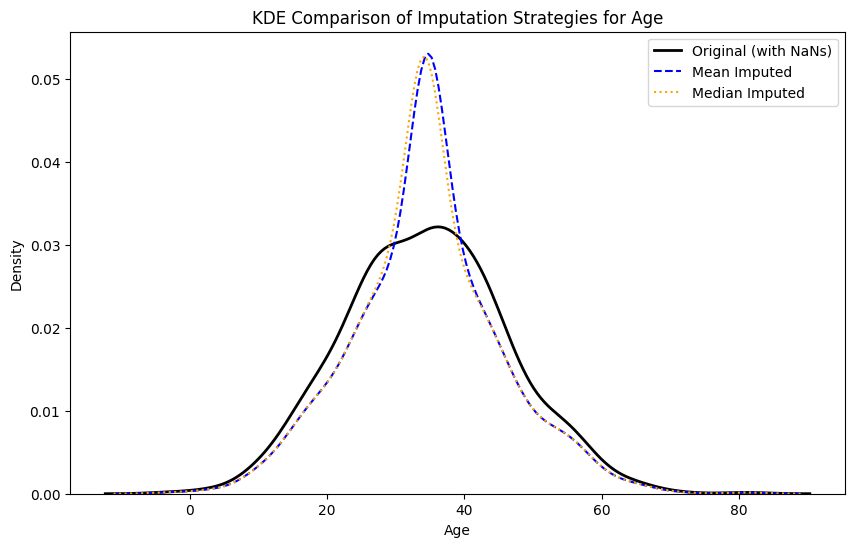

In [7]:
### Problem 5: KDE comparison of Mean vs Median Imputation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')

# Train test split to calculate values from training set only
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)

# Calculate mean and median on training data
train_mean = X_train['Age'].mean()
train_median = X_train['Age'].median()

print(f"Training Set Mean: {train_mean:.2f}")
print(f"Training Set Median: {train_median:.2f}")

# Create new imputed columns
df['Age_mean_imputed'] = df['Age'].fillna(train_mean)
df['Age_median_imputed'] = df['Age'].fillna(train_median)

# Plotting KDE
plt.figure(figsize=(10, 6))
sns.kdeplot(df['Age'], label='Original (with NaNs)', color='black', linewidth=2, warn_singular=False)
sns.kdeplot(df['Age_mean_imputed'], label='Mean Imputed', color='blue', linestyle='--')
sns.kdeplot(df['Age_median_imputed'], label='Median Imputed', color='orange', linestyle=':')
plt.title('KDE Comparison of Imputation Strategies for Age')
plt.xlabel('Age')
plt.ylabel('Density')
plt.legend()
plt.show()

# Discussion on choice:
# "Which one would you choose and why?"
# Typically, if the 'Age' distribution is highly skewed or has significant outliers,
# Median imputation is preferred because the median is robust to outliers and preserves the true shape
# of the distribution better. If 'Age' is normally distributed, mean imputation is standard.
# However, single imputation methods (mean/median) artificially spike the density peak; looking at the KDE,
# we choose the one that alters the original density distribution variance and shape the least.


### **Problem 6: Preprocessing Strategy Recommendation**

**Scenario:**
You are presented with a dataset containing the following attributes:

| Column | Missing % | Data Type | Distribution |
| :--- | :--- | :--- | :--- |
| **Income** | 15% | Numerical | Highly skewed (right tail) |
| **Rating** | 8% | Numerical | Normal (bell-shaped) |
| **City** | 5% | Categorical | 50 categories, one dominates (40%) |
| **Diagnosis** | 22% | Categorical | 3 categories (balanced: 34%, 33%, 33%) |
| **Cabin** | 68% | Categorical | Many categories, none dominant |

**Task:**
For each column, recommend the best imputation strategy and justify your choice.

In [8]:
### Problem 6: Imputation Recommendation Strategy

import pandas as pd

# Let's frame the recommendations in a structured DataFrame format for readability
recommendations = pd.DataFrame({
    'Column': ['Income', 'Rating', 'City', 'Diagnosis', 'Cabin'],
    'Missing %': ['15%', '8%', '5%', '22%', '68%'],
    'Data Type': ['Numerical', 'Numerical', 'Categorical', 'Categorical', 'Categorical'],
    'Distribution': ['Highly skewed (right tail)', 'Normal (bell-shaped)', '50 categories, one dominates (40%)', '3 categories (balanced)', 'Many categories, none dominant'],
    'Recommended Strategy': [
        'Median Imputation',
        'Mean Imputation',
        'Mode (Most Frequent) Imputation or Constant \'Unknown\'',
        'Constant Strategy (e.g., \'Missing\') + Missing Indicator',
        'Drop Column or Create a Binary Indicator \'Has_Cabin\''
    ],
    'Justification': [
        'Since Income is highly skewed, the mean would be distorted by outliers. Median represents the central tendency robustly.',
        'Since Rating follows a symmetric normal distribution, the Mean represents the central tendency optimally without distortion.',
        'Since one category dominates heavily (40%) and missing is low (5%), mode imputation is robust; alternatively, a category \'Unknown\' prevents synthetic bias.',
        'Since the classes are balanced and missingness is high (22%), mode imputation would bias the distribution. Creating a \'Missing\' label + an indicator preserves the missingness pattern.',
        'With 68% missing and no dominant category, imputation will introduce massive noise. Dropping the column or converting it to boolean (1 if Cabin exists, 0 if NaN) is the best practice.'
    ]
})

pd.set_option('display.max_colwidth', None)
display(recommendations)


,Column,Missing %,Data Type,Distribution,Recommended Strategy,Justification
0,Income,15%,Numerical,Highly skewed (right tail),Median Imputation,"Since Income is highly skewed, the mean would be distorted by outliers. Median represents the central tendency robustly."
1,Rating,8%,Numerical,Normal (bell-shaped),Mean Imputation,"Since Rating follows a symmetric normal distribution, the Mean represents the central tendency optimally without distortion."
2,City,5%,Categorical,"50 categories, one dominates (40%)",Mode (Most Frequent) Imputation or Constant 'Unknown',"Since one category dominates heavily (40%) and missing is low (5%), mode imputation is robust; alternatively, a category 'Unknown' prevents synthetic bias."
3,Diagnosis,22%,Categorical,3 categories (balanced),"Constant Strategy (e.g., 'Missing') + Missing Indicator","Since the classes are balanced and missingness is high (22%), mode imputation would bias the distribution. Creating a 'Missing' label + an indicator preserves the missingness pattern."
4,Cabin,68%,Categorical,"Many categories, none dominant",Drop Column or Create a Binary Indicator 'Has_Cabin',"With 68% missing and no dominant category, imputation will introduce massive noise. Dropping the column or converting it to boolean (1 if Cabin exists, 0 if NaN) is the best practice."
